In [19]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

## __1)__   __aa composition__ of the entire sequence in __SwissProt__ 

In [20]:
df_background=pd.read_csv('/home/um40/LB2_project_Group_1/Data_analysis/aa_composition_plots/aa_composition_swissprot.tsv',sep='\t')
df_background.rename(columns={'Percent':'freq_back','1-letter code':'aa'},inplace=True)
df_background['freq_back']=(df_background['freq_back']
                        .str.replace('%', '', regex=False)
                        .astype(float))


df_background['freq_back']/=100


## __2) aa composition__ of __SPs sequences__

In [21]:
from collections import Counter

file_path='/home/um40/LB2_project_Group_1/Data_preparation/Data_cleaning/positive_set.cluster/cluster-results-positive_rep_seq.fasta'
data = pd.read_csv('/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv', sep='\t')


def count_aa(file_path,start=0):
    #inizializzo il dizionario con le 20 lettere dell'alfabeto delle proteine e con valore iniziale 0
    keys = "ACDEFGHIKLMNPQRSTVWY" 
    dict_aa= Counter({aa: 0 for aa in keys})

    with open(file_path) as file:
        for line in file:
            line=line.strip()
            if line.startswith('>') or not line:
                UniprotID = line.rstrip()[1:]
                cleavage_pos = data.loc[data['ID'] == UniprotID, 'cleavage_pos'].values[0]
                
                for aa in file.readline()[start:cleavage_pos]:
                    aa=aa.upper()
                    if aa in dict_aa:
                        dict_aa[aa]+=1

    return dict_aa


dict_aa=count_aa(file_path)
# for k,v in dict_aa.items():
#     print(f'{k}:{v}')

df_pos = pd.DataFrame({'aa': dict_aa.keys(), 'count': dict_aa.values()})
df_pos['freq_pos']=df_pos['count']/sum(dict_aa.values())


df = pd.merge(df_pos[['aa', 'freq_pos']], df_background[['aa', 'freq_back']], on='aa')
df.head()

,aa,freq_pos,freq_back
0,A,0.143342,0.0826
1,C,0.028653,0.0139
2,D,0.008762,0.0546
3,E,0.013300,0.0671
4,F,0.050320,0.0387


### __3) Bar plot__ for __aa composition__ comparison between __Background__ and __SPs__

- prova1

Text(0, 0.5, 'Frequency')

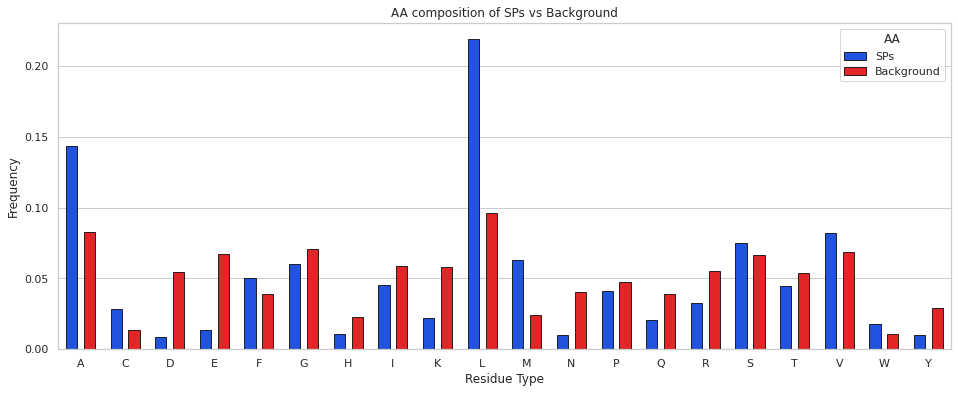

In [22]:
palette = {'SPs': "#0144fe", 'Background': "#ff0707"}
sns.set_theme(style="whitegrid")

df_melted= df.melt(id_vars='aa', value_vars=['freq_pos', 'freq_back'], var_name='AA', value_name='Frequency')
df_melted['AA'] = df_melted['AA'].map({'freq_pos': 'SPs', 'freq_back': 'Background'})

plt.figure(figsize=(16, 6))


ax = sns.barplot(data=df_melted, x='aa', y='Frequency', hue='AA',palette=palette,
    edgecolor='black',
    linewidth=0.8)

new_width = 0.25
for patch in ax.patches:
    current_width = patch.get_width()
    diff = current_width - new_width
    patch.set_width(new_width)
    patch.set_x(patch.get_x() + diff / 2)

plt.title('AA composition of SPs vs Background')
plt.xlabel('Residue Type')
plt.ylabel('Frequency')



- prova2 

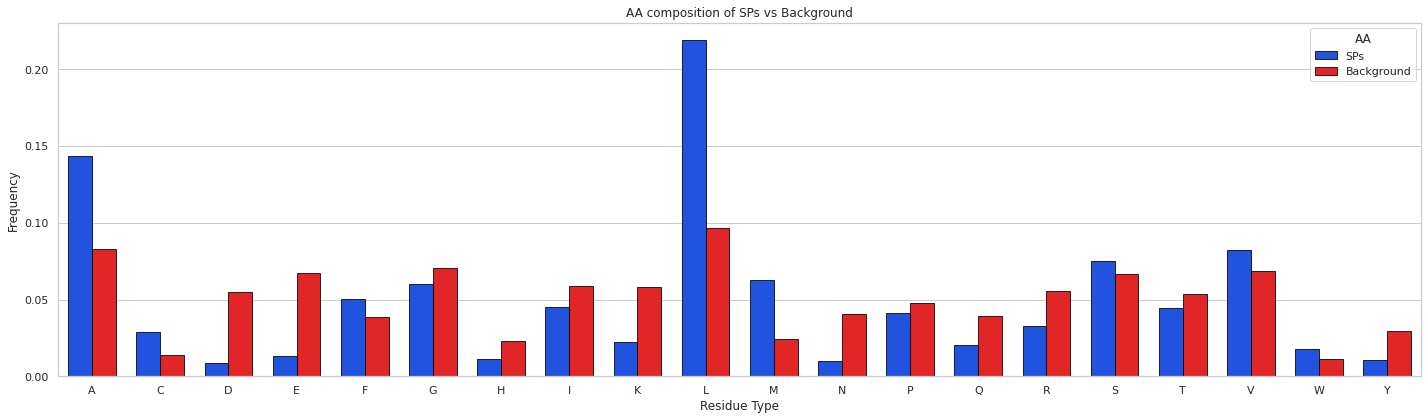

In [23]:
palette = {'SPs': "#0144fe", 'Background': "#ff0707"}
sns.set_theme(style="whitegrid")

df_melted = df.melt(id_vars='aa', value_vars=['freq_pos', 'freq_back'],
                     var_name='AA', value_name='Frequency')
df_melted['AA'] = df_melted['AA'].map({'freq_pos': 'SPs', 'freq_back': 'Background'})

plt.figure(figsize=(20, 6))
ax = sns.barplot(data=df_melted, x='aa', y='Frequency', hue='AA',
                  palette=palette, edgecolor='black', linewidth=0.8)

n = df_melted['aa'].nunique()
new_width = 0.35  # regola a piacere: più vicino a 0.4 = barre più larghe

for i in range(n):
    p1 = ax.patches[i]       # SPs
    p2 = ax.patches[i + n]   # Background
    center = (p1.get_x() + p1.get_width()/2 + p2.get_x() + p2.get_width()/2) / 2
    p1.set_width(new_width)
    p2.set_width(new_width)
    p1.set_x(center - new_width)  # attaccata a sinistra del centro
    p2.set_x(center)              # attaccata a destra del centro

ax.set_title('AA composition of SPs vs Background')
ax.set_xlabel('Residue Type')
ax.set_ylabel('Frequency')
plt.tight_layout()


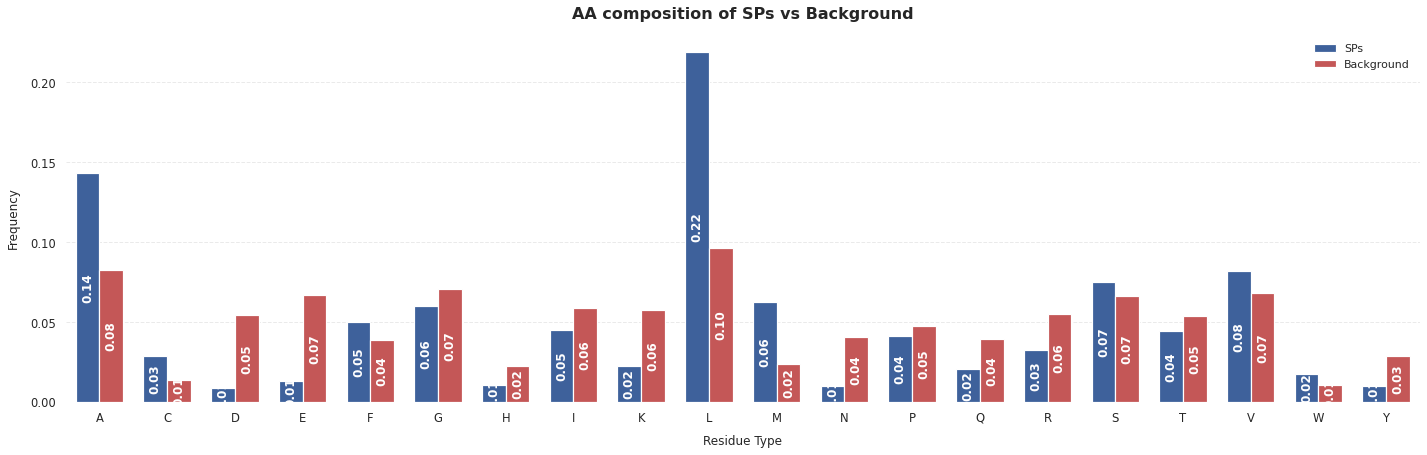

In [24]:

sns.set_theme(style="white", font_scale=1.05)
plt.rcParams['font.family'] = 'DejaVu Sans'

palette = {'SPs': "#2E5EAA", 'Background': "#D64545"}

df_melted = df.melt(id_vars='aa', value_vars=['freq_pos', 'freq_back'],
                     var_name='AA', value_name='Frequency')
df_melted['AA'] = df_melted['AA'].map({'freq_pos': 'SPs', 'freq_back': 'Background'})

fig, ax = plt.subplots(figsize=(20, 6.5))

sns.barplot(data=df_melted, x='aa', y='Frequency', hue='AA',
            palette=palette, edgecolor='white', linewidth=1.2, ax=ax)

n = df_melted['aa'].nunique()
new_width = 0.35

for i in range(n):
    p1 = ax.patches[i]
    p2 = ax.patches[i + n]
    center = (p1.get_x() + p1.get_width()/2 + p2.get_x() + p2.get_width()/2) / 2
    p1.set_width(new_width)
    p2.set_width(new_width)
    p1.set_x(center - new_width)
    p2.set_x(center)

# Etichette dentro alle barre (valore, ruotato in verticale, colore bianco)
for patch in ax.patches:
    height = patch.get_height()
    ax.text(
        patch.get_x() + patch.get_width()/2,
        height * 0.5,                      # a metà altezza della barra -> "dentro"
        f'{height:.2f}',
        ha='center', va='center',
        rotation=90,
        fontsize=12, color='white', fontweight='bold'
    )

# Pulizia estetica
ax.set_title('AA composition of SPs vs Background', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Residue Type', fontsize=12, labelpad=10)
ax.set_ylabel('Frequency', fontsize=12, labelpad=10)

sns.despine(left=True, bottom=True)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

ax.legend(title='', frameon=False, loc='upper right', fontsize=11)

plt.tight_layout()
plt.savefig("aa_background_SPs.svg", format="svg", bbox_inches="tight")
plt.show()

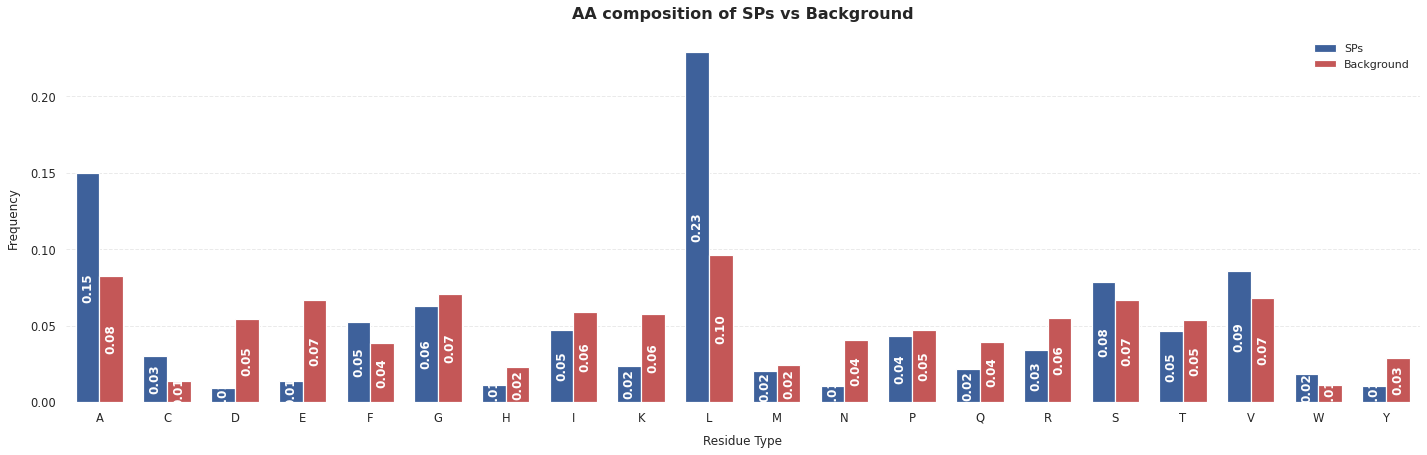

In [25]:
# per confermare bias metionina

dict_aa=count_aa(file_path,1)
# for k,v in dict_aa.items():
#     print(f'{k}:{v}')

df_pos = pd.DataFrame({'aa': dict_aa.keys(), 'count': dict_aa.values()})
df_pos['freq_pos']=df_pos['count']/sum(dict_aa.values())


df = pd.merge(df_pos[['aa', 'freq_pos']], df_background[['aa', 'freq_back']], on='aa')

sns.set_theme(style="white", font_scale=1.05)
plt.rcParams['font.family'] = 'DejaVu Sans'

palette = {'SPs': "#2E5EAA", 'Background': "#D64545"}

df_melted = df.melt(id_vars='aa', value_vars=['freq_pos', 'freq_back'],
                     var_name='AA', value_name='Frequency')
df_melted['AA'] = df_melted['AA'].map({'freq_pos': 'SPs', 'freq_back': 'Background'})

fig, ax = plt.subplots(figsize=(20, 6.5))

sns.barplot(data=df_melted, x='aa', y='Frequency', hue='AA',
            palette=palette, edgecolor='white', linewidth=1.2, ax=ax)

n = df_melted['aa'].nunique()
new_width = 0.35

for i in range(n):
    p1 = ax.patches[i]
    p2 = ax.patches[i + n]
    center = (p1.get_x() + p1.get_width()/2 + p2.get_x() + p2.get_width()/2) / 2
    p1.set_width(new_width)
    p2.set_width(new_width)
    p1.set_x(center - new_width)
    p2.set_x(center)

# Etichette dentro alle barre (valore, ruotato in verticale, colore bianco)
for patch in ax.patches:
    height = patch.get_height()
    ax.text(
        patch.get_x() + patch.get_width()/2,
        height * 0.5,                      # a metà altezza della barra -> "dentro"
        f'{height:.2f}',
        ha='center', va='center',
        rotation=90,
        fontsize=12, color='white', fontweight='bold'
    )

# Pulizia estetica
ax.set_title('AA composition of SPs vs Background', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Residue Type', fontsize=12, labelpad=10)
ax.set_ylabel('Frequency', fontsize=12, labelpad=10)

sns.despine(left=True, bottom=True)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

ax.legend(title='', frameon=False, loc='upper right', fontsize=11)

plt.tight_layout()
plt.savefig("aa_background_SPs_not_biased.svg", format="svg", bbox_inches="tight")
plt.show()

__Bias Metionina__ :
- metionina sembra più presente ma è solo un bias , perchè tutte le seq iniziano con metionina , e io vado a selezionare solo il peptide, che si trova all'inizio della proteina. è più presente ma non è informativo

- __bias metionina confermato__ dal secondo grafico, basta far iniziare la slice considerata una sola posizione più avanti per notare che la propoerzione torna ad eguagliarsi tra background e SNs


__informazioni informative__ :
- leucina , alanina e valina , ovvero gli aa idrofobici sono i più presenti , in accordo con il seq logo, poichè sono posizioni conservate nel SPs

- metre aa polari sono molto rappresentati per incompatibilità , sono meno tollerati come sostituzioni in posizioni molto conservate 

cambialo , fai concat con dim=1

### __Analisis__: AA composition is similar between SPs and Background

# _______________________________________________________________________________________________
## __4)__ comparing __k-fold and test split__ aa compositions

- creo dict per ogni fold e lo compilo leggendo il fasta e determinando il fold tramite query sul df generale 

In [26]:
data = pd.read_csv('/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv', sep='\t')

keys = "ACDEFGHIKLMNPQRSTVWY" 
    
fold1,fold2,fold3,fold4,fold5,test=(Counter({aa: 0 for aa in keys}) for i in range(6))

with open(file_path) as fasta:
    for line in fasta:
        line=line.strip()
        if line.startswith('>'):
            id = line[1:]
            fold = data.loc[data['ID'] == id, 'fold'].values[0] 
            if fold==1: dict_f=fold1
            elif fold==2: dict_f=fold2
            elif fold==3: dict_f=fold3
            elif fold==4: dict_f=fold4
            elif fold==5: dict_f=fold5
            else: dict_f=test

            for aa in fasta.readline():
                aa=aa.upper()
                if aa in dict_f:
                    dict_f[aa]+=1

counts = pd.DataFrame({
    "Fold 1": fold1, "Fold 2": fold2, "Fold 3": fold3,
    "Fold 4": fold4, "Fold 5": fold5, "Test": test,
})

#normalizzo 
df_freq = counts / counts.sum() 

df_long = (df_freq.rename_axis("AA")
               .reset_index()
               .melt(id_vars="AA", var_name="Set", value_name="Frequency"))




- prova1

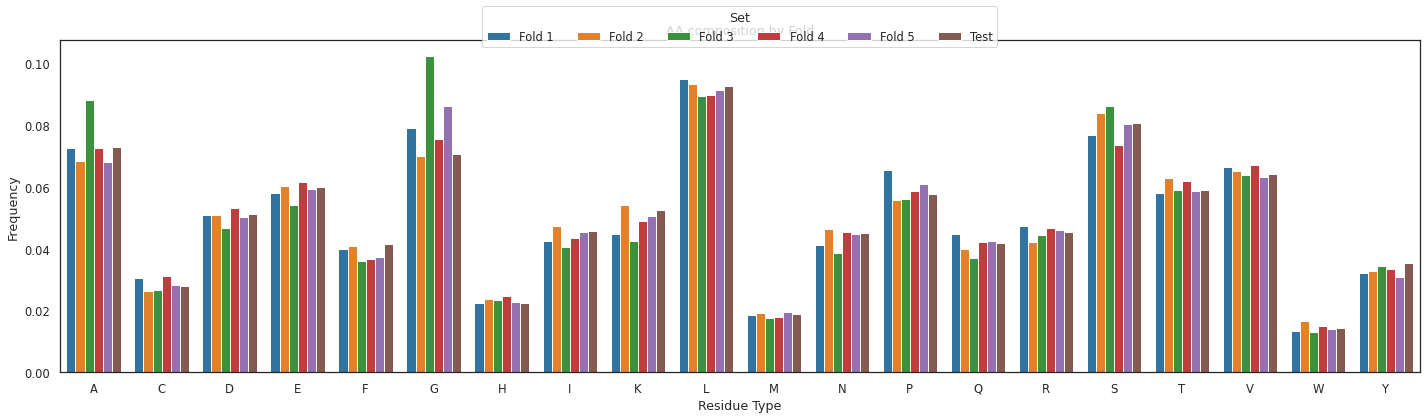

In [27]:
plt.figure(figsize=(20, 6))
sns.barplot(data=df_long, x="AA", y="Frequency", hue="Set", palette="tab10")
plt.title("AA composition by Fold")
plt.xlabel("Residue Type")
plt.legend(title="Set", ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.12))
plt.tight_layout()
plt.show()

- grafico pulito più informativo

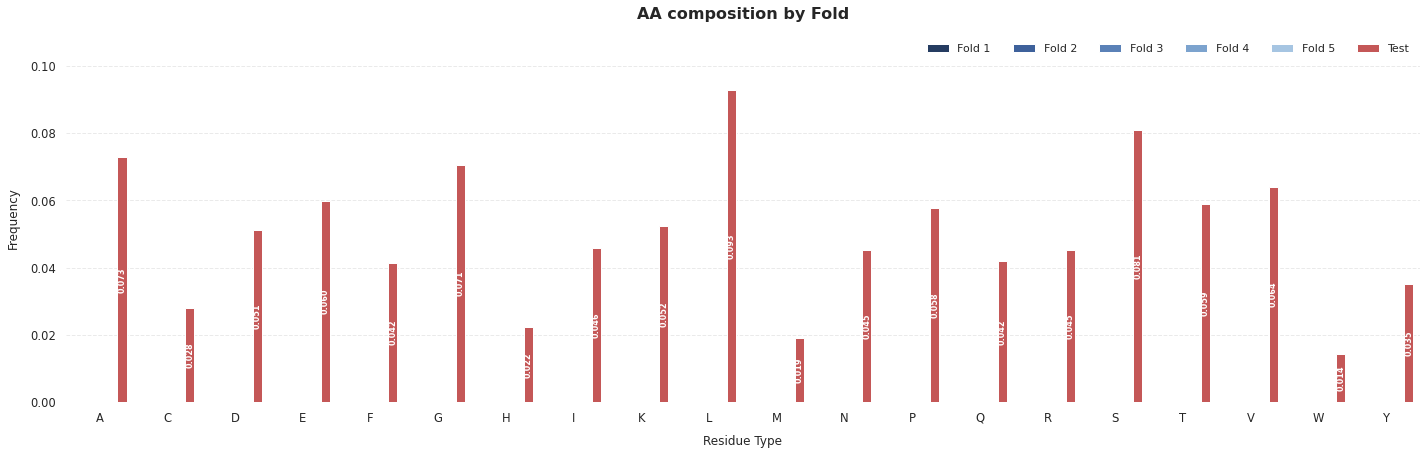

In [30]:
# Tema
sns.set_theme(style="white", font_scale=1.05)
plt.rcParams['font.family'] = 'DejaVu Sans'

         
# Palette: blu + azzurro per i fold, rosso per il test
palette = {
    "Fold 1": "#1B3A6B",
    "Fold 2": "#2E5EAA",
    "Fold 3": "#4A7FC7",
    "Fold 4": "#6FA3DB",
    "Fold 5": "#9CC5EC",
    "Test":   "#D64545",
}
hue_order = list(palette.keys())

# Plot
fig, ax = plt.subplots(figsize=(20, 6.5))

sns.barplot(data=df_long, x="AA", y="Frequency", hue="Set", hue_order=hue_order,
            palette=palette, edgecolor="white", linewidth=1.0, ax=ax)

# Etichette dentro alle barre (verticali, bianche)
for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            height * 0.5,
            f"{height:.3f}",
            ha="center", va="center", rotation=90,
            fontsize=8, color="white", fontweight="bold"
        )

# Pulizia estetica
ax.set_title("AA composition by Fold", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Residue Type", fontsize=12, labelpad=10)
ax.set_ylabel("Frequency", fontsize=12, labelpad=10)

ax.set_ylim(0, df_long["Frequency"].max() * 1.18)   

sns.despine(left=True, bottom=True)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.legend(title="", frameon=False, loc="upper right", ncol=6, fontsize=11)

plt.tight_layout()
plt.savefig("aa_composition_kfold.svg", format="svg", bbox_inches="tight")
plt.show()

### __Analisis__: AA composition is similar between the 5 k-folds and the test

# _______________________________________________________________________________________________
## __5)__ Comparing AA composition between __train__ and __test__ sets 

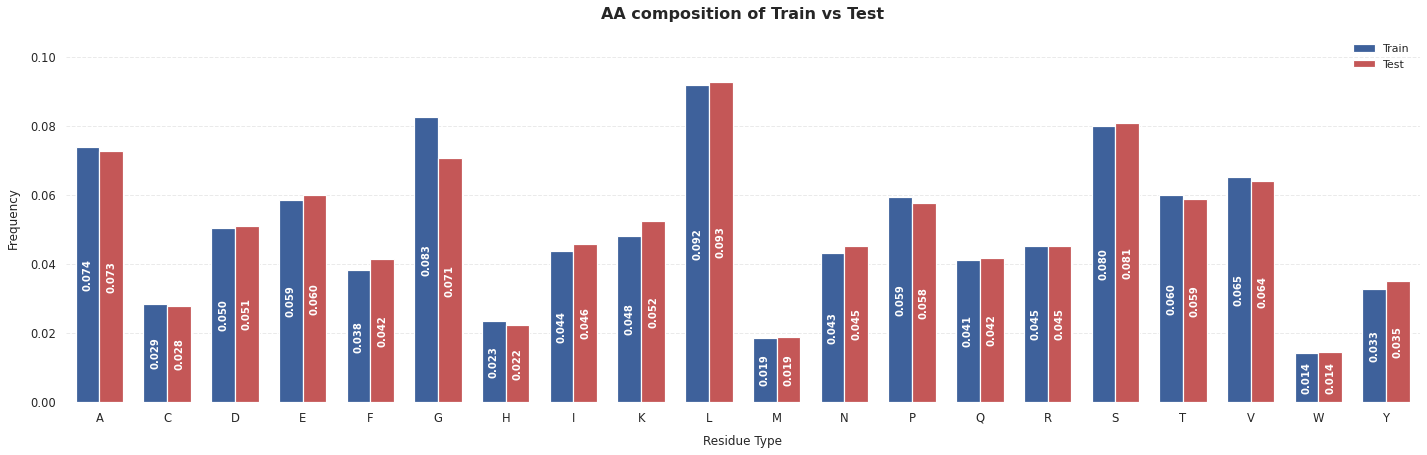

In [29]:


counts_tt = pd.DataFrame({
    "Train": counts[["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"]].sum(axis=1),
    "Test":  counts["Test"],
})

df_freq = counts_tt / counts_tt.sum()

df_long = (df_freq.rename_axis("AA")
                  .reset_index()
                  .melt(id_vars="AA", var_name="Set", value_name="Frequency"))

palette = {"Train": "#2E5EAA", "Test": "#D64545"}

fig, ax = plt.subplots(figsize=(20, 6.5))

sns.barplot(data=df_long, x="AA", y="Frequency", hue="Set", hue_order=["Train", "Test"],
            palette=palette, edgecolor="white", linewidth=1.2, ax=ax)

# Barre più strette e affiancate
n = df_long["AA"].nunique()
new_width = 0.35

for i in range(n):
    p1 = ax.patches[i]
    p2 = ax.patches[i + n]
    center = (p1.get_x() + p1.get_width() / 2 + p2.get_x() + p2.get_width() / 2) / 2
    p1.set_width(new_width)
    p2.set_width(new_width)
    p1.set_x(center - new_width)
    p2.set_x(center)

# Etichette dentro alle barre
for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            height * 0.5,
            f"{height:.3f}",
            ha="center", va="center", rotation=90,
            fontsize=10, color="white", fontweight="bold"
        )

# Pulizia estetica
ax.set_title("AA composition of Train vs Test", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Residue Type", fontsize=12, labelpad=10)
ax.set_ylabel("Frequency", fontsize=12, labelpad=10)

ax.set_ylim(0, df_long["Frequency"].max() * 1.15)

sns.despine(left=True, bottom=True)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.legend(title="", frameon=False, loc="upper right", fontsize=11)

plt.tight_layout()
plt.savefig("aa_composition_train_vs_test.svg", format="svg", bbox_inches="tight")
plt.show()

### __Analisis__: AA composition is similar between train an test sets